# Part 2: Category of Plots — Univariate Categorical & Numerical Analysis
**Course Notes Reference:** Parts 4, 5, 7 & 8

Topics covered:
- **Categorical (Univariate):** Bar chart (Matplotlib), Count plot (Seaborn), Horizontal & Sorted bars, Grouped & Stacked bars, `countplot` vs `barplot`, Pie & Donut charts
- **Numerical (Univariate):** Histogram (Matplotlib & Seaborn), Bins & Density, KDE plot, Mean/Median/Mode & Skewness, Taming right-skewed data with `np.log1p`


In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

sns.set_theme(style="whitegrid")
data = pd.read_csv("vgsales.csv")
data = data.dropna(subset=["Year", "Publisher"]).copy()
data["Year"] = data["Year"].astype(int)
data.head()


## Univariate Analysis: Categorical Data (Bar, Count, Pie, Donut)


In [2]:
# Categorical: for example Genre
data["Genre"].unique()


In [3]:
genre_counts = data["Genre"].value_counts()
genre_counts


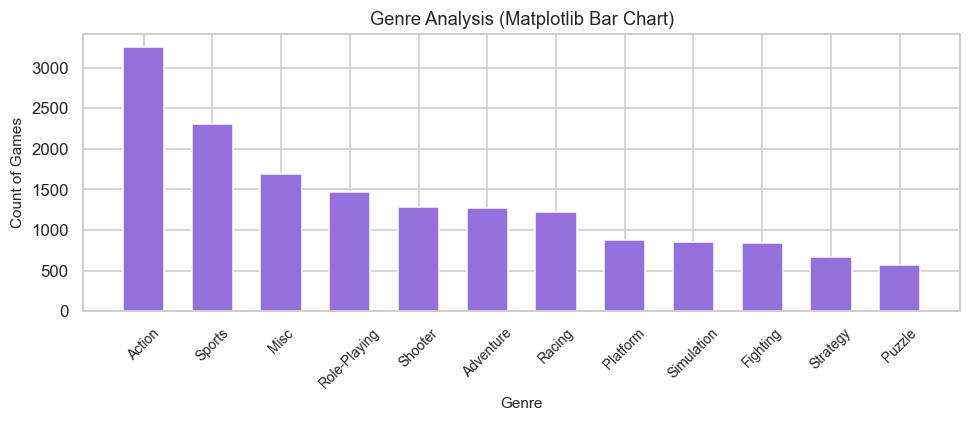

In [4]:
# BAR PLOT (Matplotlib)
x_bar = genre_counts.index
y_bar = genre_counts.values

plt.figure(figsize=(9, 4))
plt.xticks(rotation=45, fontsize=9)
plt.xlabel("Genre", fontsize=10)
plt.ylabel("Count of Games", fontsize=10)
plt.title("Genre Analysis (Matplotlib Bar Chart)", fontsize=12)
plt.bar(x_bar, y_bar, width=0.6, color="mediumpurple")
plt.tight_layout()
plt.show()


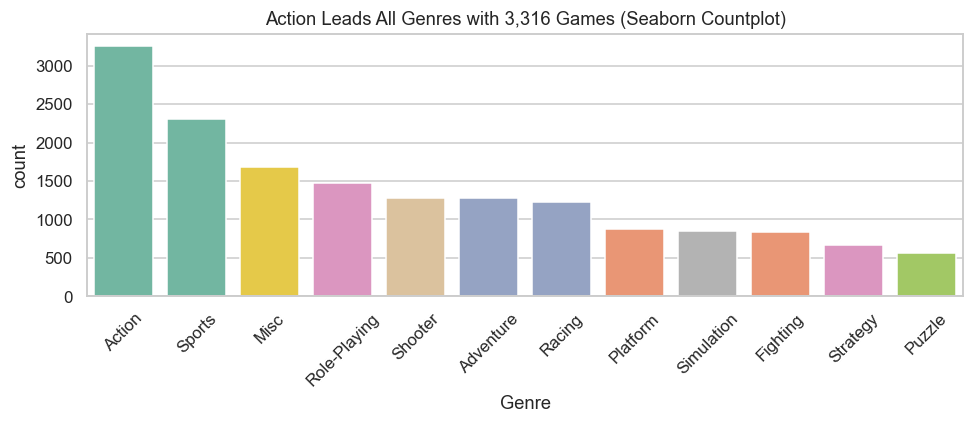

In [5]:
# COUNT PLOT (Seaborn) — sorted high to low
plt.figure(figsize=(9, 4))
sns.countplot(x="Genre", data=data, order=genre_counts.index, hue="Genre", palette="Set2", legend=False)
plt.xticks(rotation=45)
plt.title("Action Leads All Genres with 3,316 Games (Seaborn Countplot)")
plt.tight_layout()
plt.show()


### Horizontal & Sorted Bar Chart (Best for Long Labels)


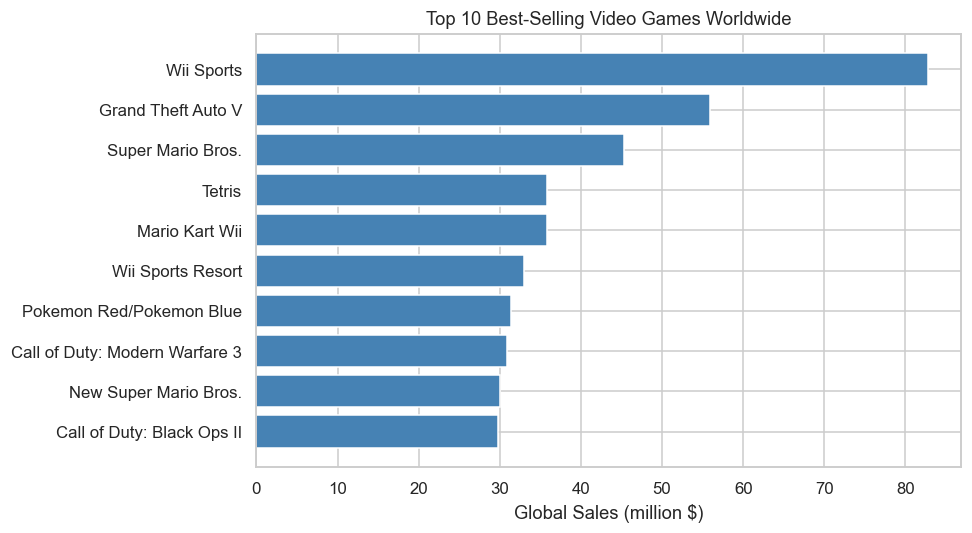

In [6]:
top10_games = data.groupby("Name")["Global_Sales"].sum().nlargest(10).sort_values()

plt.figure(figsize=(9, 5))
plt.barh(top10_games.index, top10_games.values, color="steelblue")
plt.xlabel("Global Sales (million $)")
plt.title("Top 10 Best-Selling Video Games Worldwide")
plt.tight_layout()
plt.show()


### `countplot` vs `barplot` in Seaborn


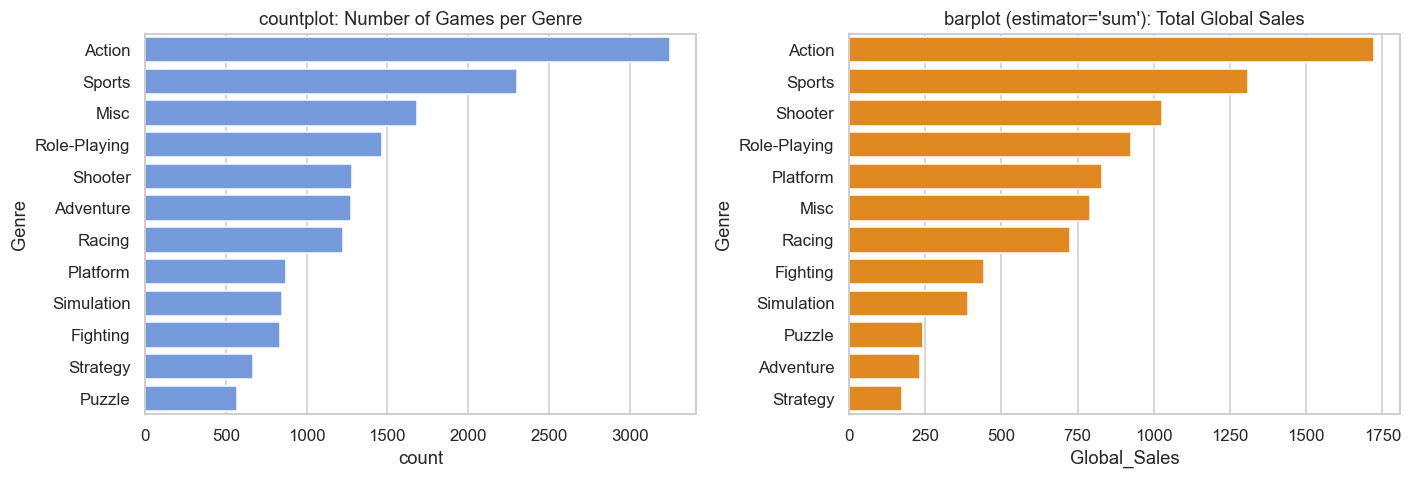

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.countplot(y="Genre", data=data, order=genre_counts.index, ax=axes[0], color="cornflowerblue")
axes[0].set_title("countplot: Number of Games per Genre")

genre_sales_order = data.groupby("Genre")["Global_Sales"].sum().sort_values(ascending=False).index
sns.barplot(y="Genre", x="Global_Sales", data=data, order=genre_sales_order,
            estimator="sum", errorbar=None, ax=axes[1], color="darkorange")
axes[1].set_title("barplot (estimator='sum'): Total Global Sales")

plt.tight_layout()
plt.show()


### Grouped & Stacked Bar Charts


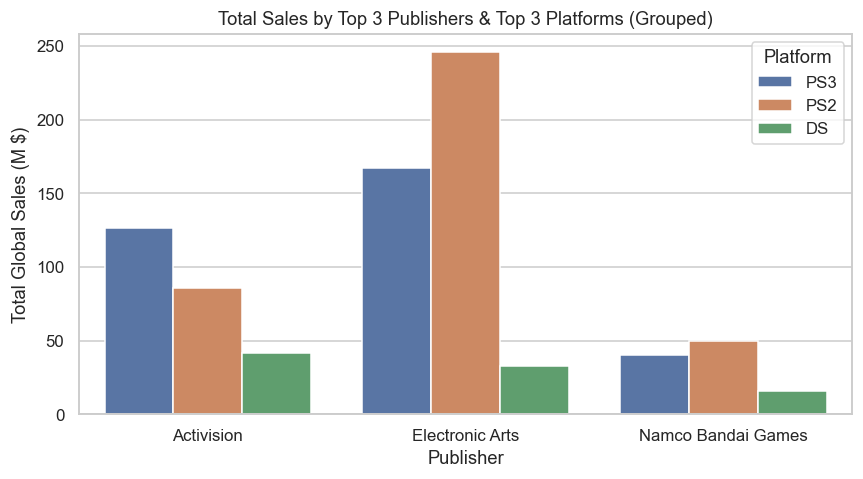

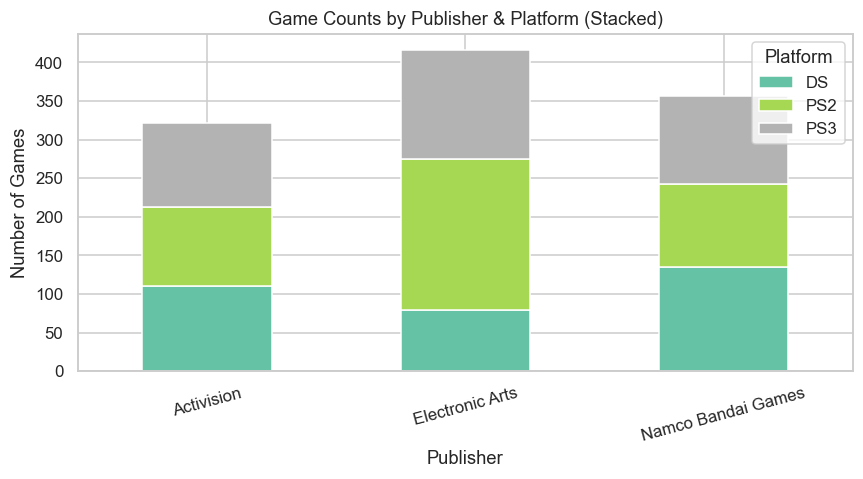

In [8]:
top3_pub = data["Publisher"].value_counts().head(3).index
top3_plat = data["Platform"].value_counts().head(3).index
sub = data[data["Publisher"].isin(top3_pub) & data["Platform"].isin(top3_plat)]

# Grouped bar (Seaborn hue)
plt.figure(figsize=(8, 4.5))
sns.barplot(x="Publisher", y="Global_Sales", hue="Platform", data=sub, estimator="sum", errorbar=None)
plt.title("Total Sales by Top 3 Publishers & Top 3 Platforms (Grouped)")
plt.ylabel("Total Global Sales (M $)")
plt.tight_layout()
plt.show()

# Stacked bar (crosstab)
ct = pd.crosstab(sub["Publisher"], sub["Platform"])
ct.plot(kind="bar", stacked=True, figsize=(8, 4.5), colormap="Set2")
plt.title("Game Counts by Publisher & Platform (Stacked)")
plt.ylabel("Number of Games")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


### Pie Chart & Donut Chart (Regional Sales Share)


In [9]:
sales_data = data[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]]
region_sales = sales_data.sum()
print(region_sales)


NA_Sales       4327.65
EU_Sales       2406.69
JP_Sales       1284.27
Other_Sales     788.91
dtype: float64


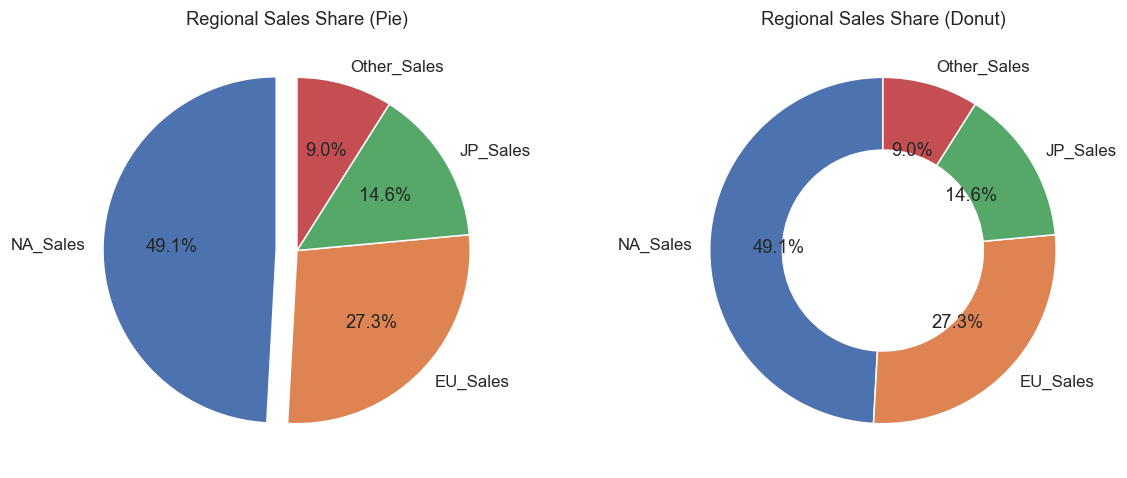

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Pie chart
axes[0].pie(
    region_sales,
    labels=region_sales.index,
    startangle=90,
    explode=(0.12, 0, 0, 0),
    autopct="%1.1f%%",
)
axes[0].set_title("Regional Sales Share (Pie)")

# Donut chart (width < 1)
axes[1].pie(
    region_sales,
    labels=region_sales.index,
    startangle=90,
    autopct="%1.1f%%",
    wedgeprops=dict(width=0.42),
)
axes[1].set_title("Regional Sales Share (Donut)")

plt.tight_layout()
plt.show()


## Univariate Analysis: Numerical Data (Histogram, KDE, Skewness & Log Transform)


In [11]:
data.describe()


Bin edges (len = bins + 1): [1980. 1984. 1988. 1992. 1996. 2000. 2004. 2008. 2012. 2016. 2020.]
Counts per bin: [ 108.   65.   89.  443. 1269. 2435. 3889. 5252. 2395.  346.]


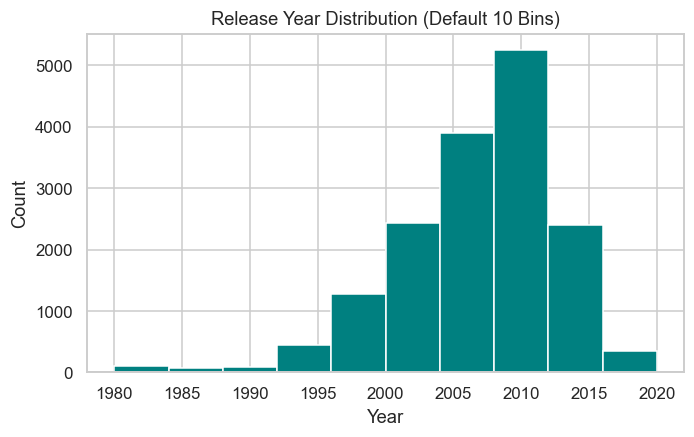

In [12]:
# Matplotlib Histogram + inspecting count & bin edges
plt.figure(figsize=(7, 4))
count, bins, _ = plt.hist(data["Year"], bins=10, edgecolor="white", color="teal")
plt.title("Release Year Distribution (Default 10 Bins)")
plt.xlabel("Year")
plt.ylabel("Count")
plt.show()

print("Bin edges (len = bins + 1):", bins)
print("Counts per bin:", count)


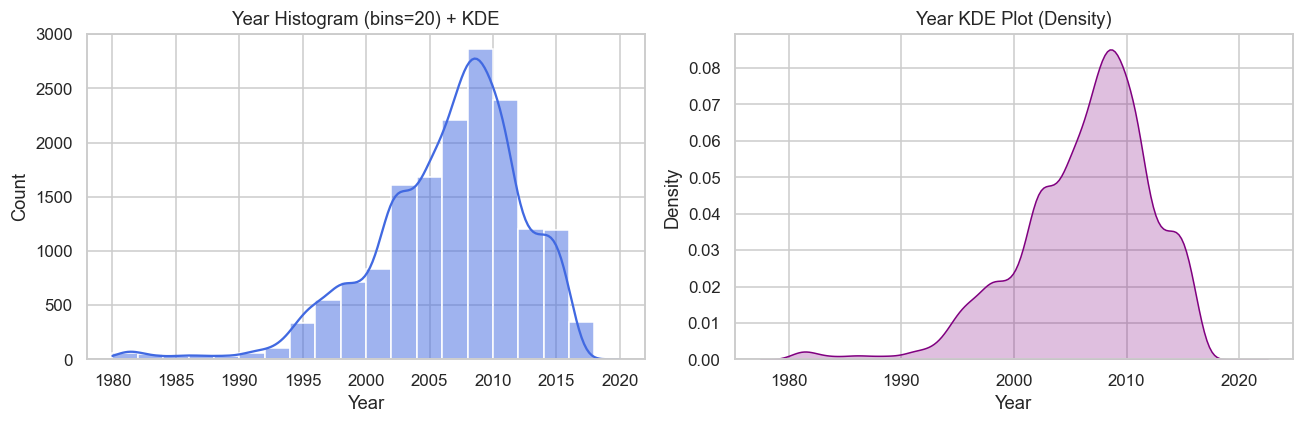

In [13]:
# Seaborn histplot with KDE & density
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data["Year"], bins=20, kde=True, ax=axes[0], color="royalblue")
axes[0].set_title("Year Histogram (bins=20) + KDE")

sns.kdeplot(data["Year"], fill=True, ax=axes[1], color="purple")
axes[1].set_title("Year KDE Plot (Density)")

plt.tight_layout()
plt.show()


### Skewness & Taming Right-Skewed Data with `np.log1p`


Global_Sales skewness: 17.3
Mean: 0.541 | Median: 0.17 | Mode: 0.02


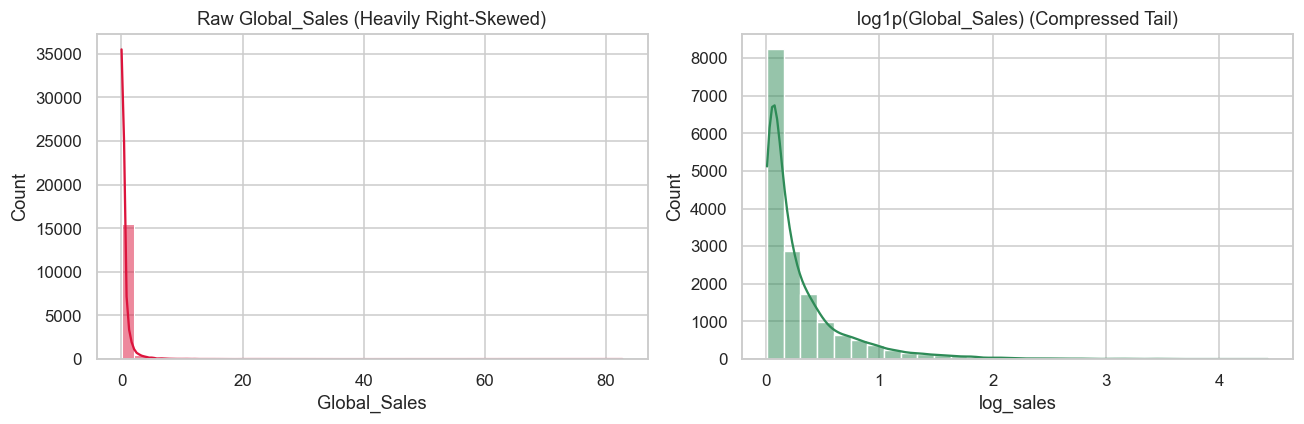

In [14]:
print("Global_Sales skewness:", round(data["Global_Sales"].skew(), 2))
print("Mean:", round(data["Global_Sales"].mean(), 3),
      "| Median:", round(data["Global_Sales"].median(), 3),
      "| Mode:", round(data["Global_Sales"].mode()[0], 3))

data["log_sales"] = np.log1p(data["Global_Sales"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data["Global_Sales"], bins=40, kde=True, ax=axes[0], color="crimson")
axes[0].set_title("Raw Global_Sales (Heavily Right-Skewed)")

sns.histplot(data["log_sales"], bins=30, kde=True, ax=axes[1], color="seagreen")
axes[1].set_title("log1p(Global_Sales) (Compressed Tail)")

plt.tight_layout()
plt.show()
